# Experimentation
---
In this notebook, we experiment with different functino settings, base data, files, concepts and visualisations. The goal is to find the best way to convey the findings of our research, both in terms of visualisation, but also in terms of metrics which are used for the communication.

In [1]:
%load_ext autoreload
%autoreload 2

import pandas as pd
import matplotlib.pyplot as plt

from cycler import cycler
from kiln_ring_analysis_function import kiln_ring_analysis, DEFAULTS as ANALYSIS_DEFAULTS
from plot_kiln_rings_function import plot_kiln_rings, DEFAULTS as PLOT_DEFAULTS
from semivariogram_function import kiln_semivariogram, plot_semivariogram


For a constant look, we define a colour scheme to be used for all graphs:

In [ ]:
COLSCHEME = {
       "ember":  ["#FDBE85", "#F68C3A", "#D9541A"],
       "forest": ["#A8DDB5", "#4DAF6E", "#23794A"],
       "smoke":  ["#A6CEE3", "#4A90C8", "#2563A0"]
       }

***
## Display raw data
In this chapter we will start with 16 rays, 1m sample intervals and 6m ring intervals (up to 24m). The samples are not weighted.  

The analysis results are saved in: `new testfolder/results/merged_dem_rays16_step1_ring6x4`

### Run analysis

In [21]:
params = {
    "gpkg": "kohlmeiler_2056.gpkg",
    "tif": "merged_dem.tif",
    "rings": [(0, 6), (6, 12), (12, 18), (18, 24)],
    "n_rays": 16,
    "step": 1,
    "weighted": False
}

out = kiln_ring_analysis(params)

samples = pd.read_csv("results/merged_dem_rays16_step1_ring6x4/merged_dem_samples.csv")
rings = [(0, 6), (6, 12), (12, 18), (18, 24)]

Raster:        merged_dem.tif
Band:          1 of 1 (no name)
CRS:           EPSG:2056
Pixel size:    1.0 x 1.0 m
Nodata value:  -999999.0
Kilns:         80 from kohlmeiler_2056.gpkg
Rays:          16 (every 22.5°), sample every 1 m up to 24 m
Weighted:      False
Centre used:   False
Samples per ring (identical for every kiln):
       0-6     m: 96 samples
       6-12    m: 96 samples
      12-18    m: 96 samples
      18-24    m: 96 samples

Overview across all kilns (each kiln = one ring mean, unweighted):
        0-6 m  6-12 m  12-18 m  18-24 m
count   79.00   79.00    79.00    79.00
median   6.20    5.93     6.14     6.06
mean     6.73    6.45     6.39     6.53
std      3.88    3.55     3.50     3.37
min      0.00    0.00     0.00     0.19
25%      4.66    4.60     4.23     4.79
50%      6.20    5.93     6.14     6.06
75%      8.54    8.56     7.47     7.86
max     19.02   16.17    17.76    17.15

Rings left empty (too little valid data):
   mean_0_6: kilns [12]
   mean_6_12: kiln

### Plot function
Here, we define a function for plotting the raw outpur of the analysis. It plots each ray of each kiln. The function includes the possibility to smooth the output of each ray with a moving window. This is done to reduce the impact that noise has on the visualisation, hiding the trends we are looking for.

In [22]:
def plot_raw_rays(samples: pd.DataFrame, rings: list, window_size=1, l_alpha=0.1, st_dev=False, color=COLSCHEME):
    samples = samples.sort_values(["kiln_id", "ray", "distance"])
    samples["smooth"] = (samples.groupby(["kiln_id", "ray"])["value"].transform(lambda v: v.rolling(window_size, center=True, min_periods=1).mean()))

    fig, ax = plt.subplots(figsize=(8,5))

    # all lines
    for _, line in samples.groupby(["kiln_id", "ray"]):
        ax.plot(line["distance"], line["smooth"], color=color["forest"][1], alpha=l_alpha, lw=0.8)

    # median, mean, stdev lines
    per_dist = samples.groupby("distance")["smooth"]
    ax.plot(per_dist.mean().index, per_dist.mean(), color=color["smoke"][2], lw=1.5, label="Mean")
    ax.plot(per_dist.median().index, per_dist.median(), color=color["smoke"][2], lw=1.5, ls="--", alpha=0.8, label="Median")
    if st_dev:
        m, s = per_dist.mean(), per_dist.std()
        ax.fill_between(m.index, m - s, m + s, color="darkgreen", alpha=0.15, label="Mean ± 1 SD")

    # ring interval boundaries
    for _, outer in rings[:-1]:
        ax.axvline(outer, color="black", lw=0.6, ls=":", alpha=0.6)

    ax.set_xlim(1,rings[-1][-1])
    ax.set_ylim(0, max(samples["smooth"])+2)
    ax.set_xlabel("Distance from kiln (m)")
    if window_size == 1:
        ax.set_ylabel(f"Canopy height (m)")
    else:
        ax.set_ylabel(f"Smoothed canopy height (m) (window={window_size})")
    ax.legend(frameon=False)
    ax.spines[["top", "right"]].set_visible(False)
    fig.tight_layout()
    return fig

### Plotting
We can now play with the plotting settings.

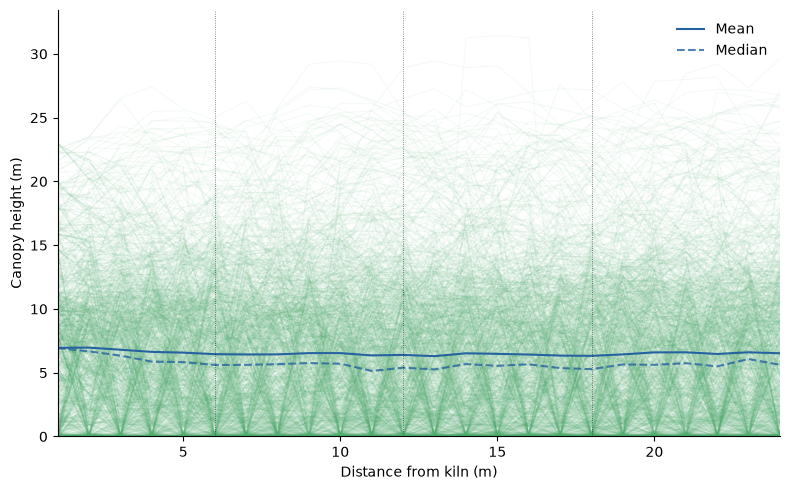

In [24]:
res_1 = plot_raw_rays(samples=samples, rings=rings, window_size=1, l_alpha=0.06)
res_1.savefig("results/merged_dem_rays16_step1_ring6x4/ray_profiles_raw.png", dpi=400)

This plot is very messy. Mainly due to the zig zag pattern at the bottom which is a result of pixels with value 0 representing the floor. There are a lot of rays that have floor pixels in the so this zig zag pattern cannot be avoided when plotting the raw pixel data.  

What can be seen is that on the very left, rays share pixel values due to the number of rays and the liimited number of pixels for small radii. This results in these few darker lines, indicating shared values. Once the radius is large enough that each ray has its own pixels, such artefacts disappear.  

**Floating average**  

What we can do is calculate a floating average for each pixel with a given window size. Let's try it with window size = 3 (i.e. it looks one pixel to the left and one to the right)

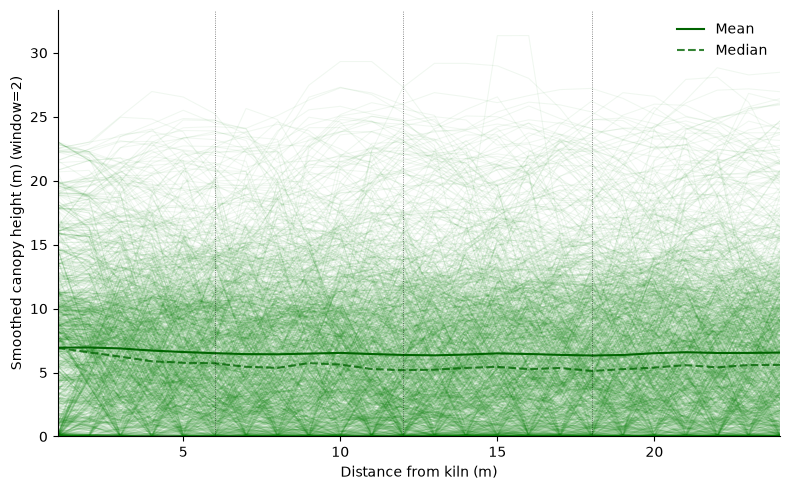

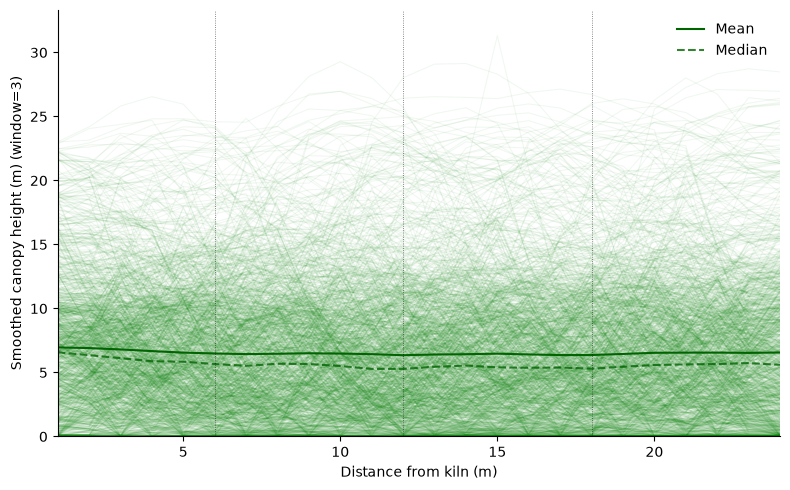

In [42]:
res_2 = plot_raw_rays(samples=samples, window_size=2, l_alpha=0.06)
res_3 = plot_raw_rays(samples=samples, window_size=3, l_alpha=0.06)

I don't know, whether these last 3 graphs are suitable for the report since the idea of this kind of graph is to truly show the data and how it looks like. The zig zag is not an artefact, it's part of the data. And the median and mean lines can still be interpreted well.

## 8 rings of 6m with 8 rays

In [25]:
params = {
    "gpkg": "kohlmeiler_2056.gpkg",
    "tif": "merged_dem.tif",
    "rings": [(0, 6), (6, 12), (12, 18), (18, 24), (24, 30), (30, 36), (36, 42), (42, 48)],
    "n_rays": 8,
    "step": 1,
    "weighted": False
}

out = kiln_ring_analysis(params)

samples = pd.read_csv("results/merged_dem_rays8_step1_ring6x8/merged_dem_samples.csv")
rings = [(0, 6), (6, 12), (12, 18), (18, 24), (24, 30), (30, 36), (36, 42), (42, 48)]

Raster:        merged_dem.tif
Band:          1 of 1 (no name)
CRS:           EPSG:2056
Pixel size:    1.0 x 1.0 m
Nodata value:  -999999.0
Kilns:         80 from kohlmeiler_2056.gpkg
Rays:          8 (every 45°), sample every 1 m up to 48 m
Weighted:      False
Centre used:   False
Samples per ring (identical for every kiln):
       0-6     m: 48 samples
       6-12    m: 48 samples
      12-18    m: 48 samples
      18-24    m: 48 samples
      24-30    m: 48 samples
      30-36    m: 48 samples
      36-42    m: 48 samples
      42-48    m: 48 samples

Overview across all kilns (each kiln = one ring mean, unweighted):
        0-6 m  6-12 m  12-18 m  18-24 m  24-30 m  30-36 m  36-42 m  42-48 m
count   79.00   79.00    79.00    79.00    79.00    77.00    79.00    79.00
median   6.11    5.52     5.73     6.14     5.93     6.03     6.35     6.05
mean     6.74    6.40     6.40     6.50     6.46     6.77     6.83     6.45
std      3.87    3.62     3.69     3.58     3.20     3.47     3.47  

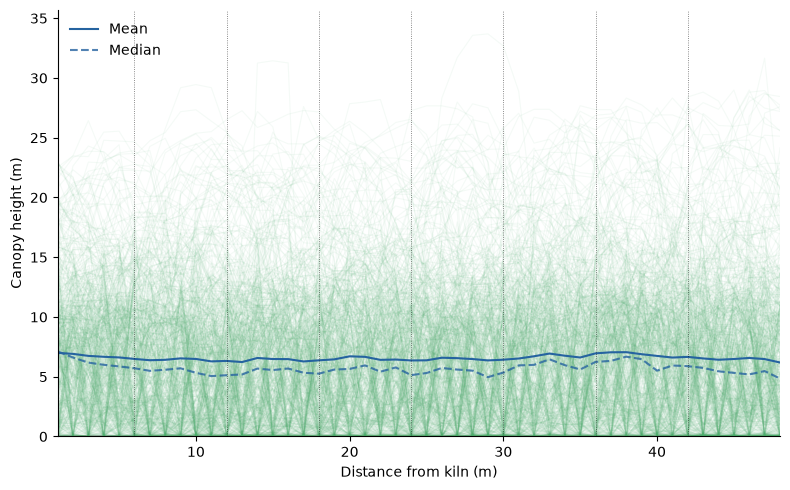

In [27]:
res_1 = plot_raw_rays(samples=samples, rings=rings, window_size=1, l_alpha=0.06)
res_1.savefig("results/merged_dem_rays8_step1_ring6x8/ray_profiles_raw.png", dpi=400)

Raster:        merged_dem.tif
Band:          1 of 1 (no name)
CRS:           EPSG:2056
Pixel size:    1.0 x 1.0 m
Nodata value:  -999999.0
Kilns:         80 from kohlmeiler_2056.gpkg
Rays:          8 (every 45°), sample every 1 m up to 36 m
Weighted:      False
Centre used:   False
Samples per ring (identical for every kiln):
       0-6     m: 48 samples
       6-12    m: 48 samples
      12-18    m: 48 samples
      18-24    m: 48 samples
      24-30    m: 48 samples
      30-36    m: 48 samples

Overview across all kilns (each kiln = one ring mean, unweighted):
        0-6 m  6-12 m  12-18 m  18-24 m  24-30 m  30-36 m
count   79.00   79.00    79.00    79.00    79.00    77.00
median   6.11    5.52     5.73     6.14     5.93     6.03
mean     6.74    6.40     6.40     6.50     6.46     6.77
std      3.87    3.62     3.69     3.58     3.20     3.47
min      0.00    0.00     0.00     0.00     0.64     0.62
25%      4.70    4.61     4.13     4.46     4.67     4.68
50%      6.11    5.52   

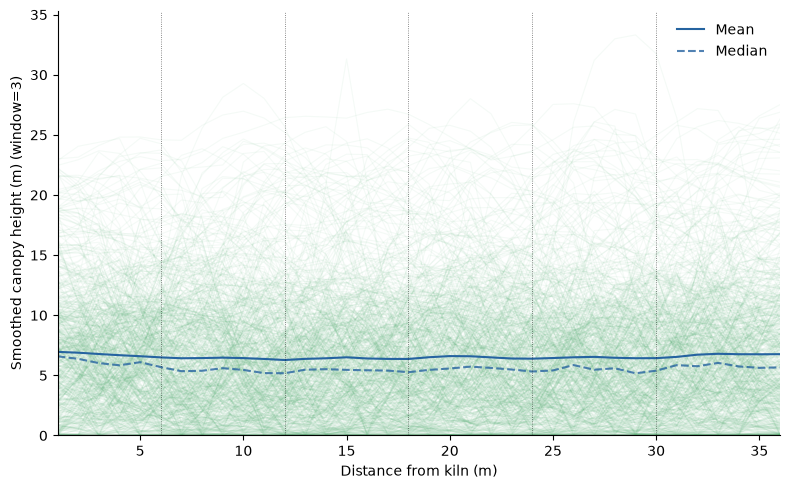

In [29]:
params = {
    "gpkg": "kohlmeiler_2056.gpkg",
    "tif": "merged_dem.tif",
    "rings": [(0, 6), (6, 12), (12, 18), (18, 24), (24, 30), (30, 36)],
    "n_rays": 8,
    "step": 1,
    "weighted": False
}

out = kiln_ring_analysis(params)

samples = pd.read_csv("results/merged_dem_rays8_step1_ring6x6/merged_dem_samples.csv")
rings = [(0, 6), (6, 12), (12, 18), (18, 24), (24, 30), (30, 36)]

res_1 = plot_raw_rays(samples=samples, rings=rings, window_size=3, l_alpha=0.06)
res_1.savefig("results/merged_dem_rays8_step1_ring6x6/ray_profiles_raw2.png", dpi=400)

## Semivariogram
To assess the scale of spatial autocorrelation in surface height, and thus how far apart samples must be to count as independent, we computed an empirical semivariogram (Matheron, 1963; Webster & Oliver, 2007). For each of the [80] charcoal kiln sites, a 100 m × 100 m window centred on the kiln was extracted from the [normalised] surface height raster (pixel size [x] m). Within each window, all pairs of pixels up to 40 m apart were formed along four directions (east–west, north–south and both diagonals), and the semivariance was calculated as half the mean squared difference in height between the two pixels of each pair, γ(h) = ½ · mean[(z(x) − z(x + h))²]. Pairs containing missing values were excluded. Pairs from all windows were pooled and binned to the nearest pixel size, giving a single omnidirectional semivariogram. [Before the calculation, a least-squares plane was subtracted from each window to remove the effect of terrain slope.] The range, i.e. the distance at which the semivariogram levels off at its sill, was taken as the scale beyond which surface heights are approximately independent. Following Woodcock et al. (1988) and Cohen et al. (1990), who showed that the semivariogram range of forest canopies reflects the size of tree crowns, we interpret it as the characteristic scale of canopy structure, and used it to inform the choice of ring width.

80 windows of 100 x 100 m, pixel size 1.0 m


<Axes: xlabel='Distance between pixels (m)', ylabel='Semivariance (m²)'>

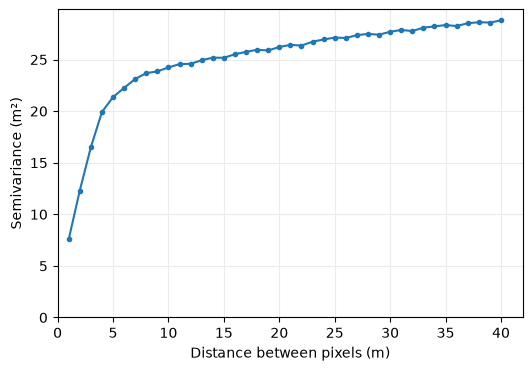

In [ ]:
sv = kiln_semivariogram({"tif": "merged_dem.tif"})
plot_semivariogram(sv)

80 windows of 100 x 100 m, pixel size 1.0 m


<Axes: xlabel='Distance between pixels (m)', ylabel='Semivariance (m²)'>

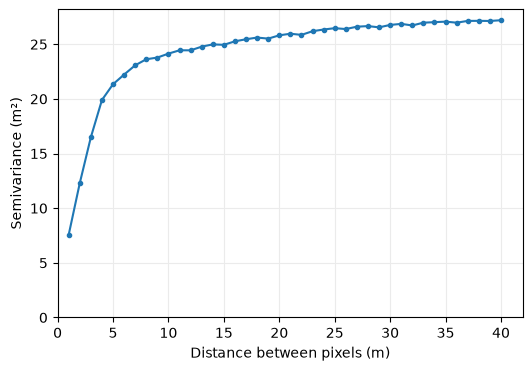

In [3]:
sv = kiln_semivariogram({"tif": "merged_dem.tif", "detrend":True})
plot_semivariogram(sv)